# 流量与趋势

用 2017-11-25 ~ 2017-12-03 共 9 天的淘宝用户行为数据，回答 4 个问题：

1. 整体流量规模有多大？日均 PV / UV 是多少？
2. 9 天里流量是涨是跌？有没有明显的高峰日？
3. 用户一天中什么时段最活跃？该在什么时间做推送？
4. 浏览、加购、收藏、购买四类行为的比例关系如何？

## 导入必要的库


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 让图表正常显示中文和负号
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 1. 导入数据：只读需要的列

完整的清洗后数据约 1 亿行、5.7GB。本分析只用到「用户、行为类型、时间」三列，
所以用 `usecols` 只读这三列，再用 `dtype` 压缩类型，内存可以降到 1GB 左右。

注意清洗文件是用 `utf-8-sig` 保存的（开头带 BOM），读的时候要指定同样的编码，否则列名会对不上。

In [2]:
data = pd.read_csv(
    'data/UserBehavior_clean.csv',
    usecols=['user_id', 'behavior_type', 'timestamp'],
    dtype={'user_id': 'int32', 'behavior_type': 'category', 'timestamp': 'int64'},
    encoding='utf-8-sig',
)
print(data.shape)
data.head()

(100150807, 3)


,user_id,behavior_type,timestamp
0,1,pv,1511544070
1,1,pv,1511561733
2,1,pv,1511572885
3,1,pv,1511593493
4,1,pv,1511596146


In [4]:
# 只保留分组要用到的两个小字段，然后丢掉 datetime 列，释放约 800MB 内存
data['day_idx'] = data['dt'].dt.day_of_year.astype('int16')
data['hour'] = data['dt'].dt.hour.astype('int8')
data['is_pv'] = (data['behavior_type'] == 'pv').astype('int8')
data['is_buy'] = (data['behavior_type'] == 'buy').astype('int8')
data = data.drop(columns=['dt', 'timestamp'])
data.dtypes

user_id             int32
behavior_type    category
day_idx             int16
hour                 int8
is_pv                int8
is_buy               int8
dtype: object

## 2. 数据校验

确认行为类型只有 4 种、日期正好覆盖 9 天。

In [5]:
print('行为类型分布:')
print(data['behavior_type'].value_counts())
print()
print('覆盖天数:', data['day_idx'].nunique())
print('跨小时数:', data['hour'].nunique())

行为类型分布:


behavior_type
pv      89660688
cart     5530446
fav      2888258
buy      2015839
Name: count, dtype: int64



覆盖天数: 9


跨小时数: 24


## 3. 核心指标概览

- **PV**：页面浏览量，这里是 `pv` 行为的条数
- **UV**：独立访客数，按 `user_id` 去重
- 日均值 = 总计 / 9 天

In [6]:
total_rows = len(data)
pv = int(data['is_pv'].sum())
uv = int(data['user_id'].nunique())
days = data['day_idx'].nunique()

# UV 是去重人数，不能跨天相加，所以日均 UV 要按「每天 UV 的平均」算
avg_daily_uv = int(data.groupby('day_idx')['user_id'].nunique().mean())

summary = pd.Series({
    '总行为数': total_rows,
    '总浏览量 PV': pv,
    '独立用户数 UV': uv,
    '覆盖天数': days,
    '日均 PV': round(pv / days),
    '日均 UV（按天平均）': avg_daily_uv,
    '人均行为数': round(total_rows / uv, 1),
    '人均浏览量': round(pv / uv, 1),
})
summary.to_frame('数值')

,数值
总行为数,100095231.0
总浏览量 PV,89660688.0
独立用户数 UV,987991.0
覆盖天数,9.0
日均 PV,9962299.0
日均 UV（按天平均）,774282.0
人均行为数,101.3
人均浏览量,90.8


## 4. 行为类型结构

看四类行为的量级差异：浏览是入口，加购/收藏是意向，购买是结果。

In [7]:
beh = data['behavior_type'].value_counts().reindex(['pv', 'cart', 'fav', 'buy'])
beh.index = ['浏览 pv', '加购 cart', '收藏 fav', '购买 buy']
share = (beh / beh.sum() * 100).round(2)
pd.DataFrame({'行为次数': beh, '占比(%)': share})

,行为次数,占比(%)
浏览 pv,89660688,89.58
加购 cart,5530446,5.53
收藏 fav,2888258,2.89
购买 buy,2015839,2.01


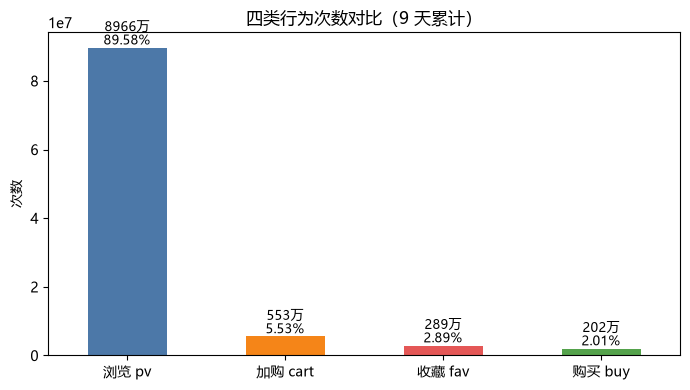

In [8]:
ax = beh.plot(kind='bar', figsize=(7, 4),
              color=['#4C78A8', '#F58518', '#E45756', '#54A24B'])
ax.set_title('四类行为次数对比（9 天累计）')
ax.set_xlabel('')
ax.set_ylabel('次数')
ax.set_xticklabels(beh.index, rotation=0)
for i, v in enumerate(beh):
    ax.text(i, v, f'{v / 1e4:.0f}万\n{share.iloc[i]}%', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 5. 每日 PV / UV 趋势

按天汇总 PV、UV 和下单量，看 9 天里的走势。

In [9]:
daily = pd.DataFrame({
    'PV': data.groupby('day_idx')['is_pv'].sum(),
    'UV': data.groupby('day_idx')['user_id'].nunique(),
    '下单量': data.groupby('day_idx')['is_buy'].sum(),
})
# 把 dayofyear 换成 11-25 这样的日期标签
daily.index = [(pd.Timestamp('2017-01-01') + pd.Timedelta(days=int(d) - 1)).strftime('%m-%d')
               for d in daily.index]
daily

,PV,UV,下单量
11-25,9353423,706641,201145
11-26,9567423,715516,205644
11-27,9041187,710094,226835
11-28,8842933,709257,212000
11-29,9210821,718922,223072
11-30,9358998,730597,221463
12-01,9718959,740139,210016
12-02,12329644,970401,257907
12-03,12237300,966977,257757


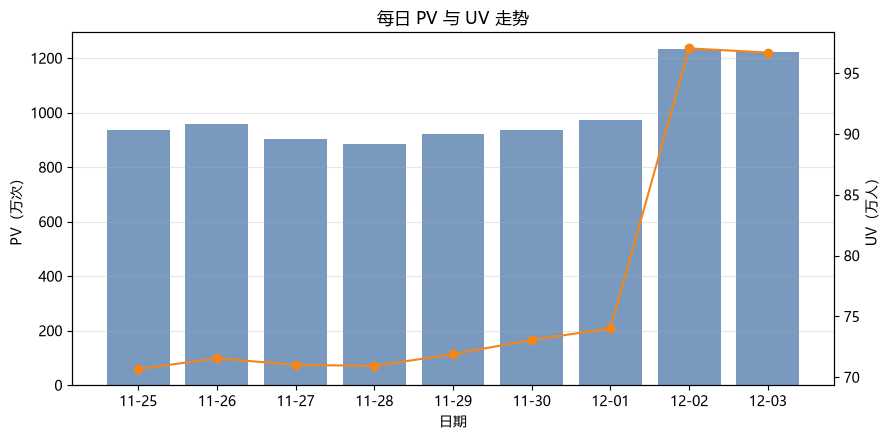

In [10]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(daily.index, daily['PV'] / 1e4, color='#4C78A8', alpha=0.75, label='PV（万次）')
ax1.set_xlabel('日期')
ax1.set_ylabel('PV（万次）')
ax1.grid(axis='y', alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(daily.index, daily['UV'] / 1e4, color='#F58518', marker='o', label='UV（万人）')
ax2.set_ylabel('UV（万人）')

ax1.set_title('每日 PV 与 UV 走势')
plt.tight_layout()
plt.show()

## 6. 用户活跃时段

按小时汇总 9 天的数据，找出一天中的活跃高峰和低谷。

In [11]:
hourly = pd.DataFrame({
    'PV': data.groupby('hour')['is_pv'].sum(),
    'UV': data.groupby('hour')['user_id'].nunique(),
    '下单量': data.groupby('hour')['is_buy'].sum(),
})
hourly['PV占比(%)'] = (hourly['PV'] / hourly['PV'].sum() * 100).round(2)
hourly

,PV,UV,下单量,PV占比(%)
hour,,,,
0,3056936,318390,57776,3.41
1,1421673,167416,23169,1.59
2,769269,98335,12012,0.86
3,524992,71415,8026,0.59
4,449628,64213,6748,0.50
5,581694,84444,8135,0.65
6,1226653,179928,18014,1.37
7,2228959,329994,37679,2.49
8,3042342,444398,64917,3.39


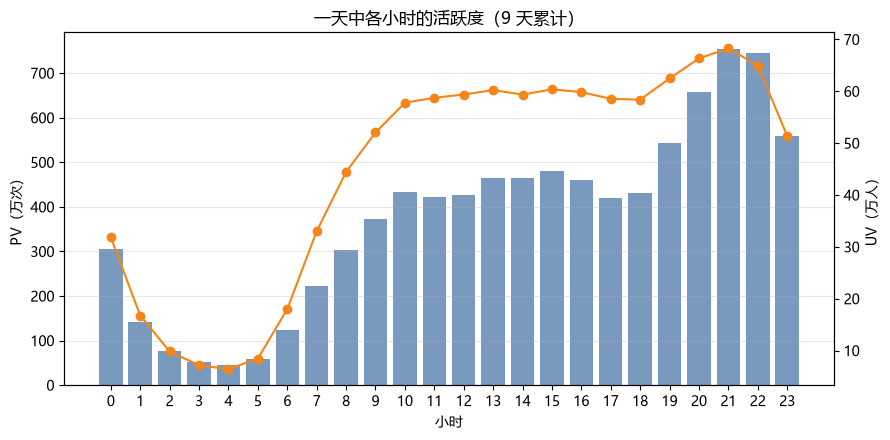

In [12]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(hourly.index, hourly['PV'] / 1e4, color='#4C78A8', alpha=0.75)
ax1.set_xlabel('小时')
ax1.set_ylabel('PV（万次）')
ax1.set_xticks(range(24))
ax1.grid(axis='y', alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly['UV'] / 1e4, color='#F58518', marker='o')
ax2.set_ylabel('UV（万人）')

ax1.set_title('一天中各小时的活跃度（9 天累计）')
plt.tight_layout()
plt.show()

## 7. 日期 × 小时 热力图

把「哪天」和「几点」叠在一起看，能同时看出日内节律和日间差异。

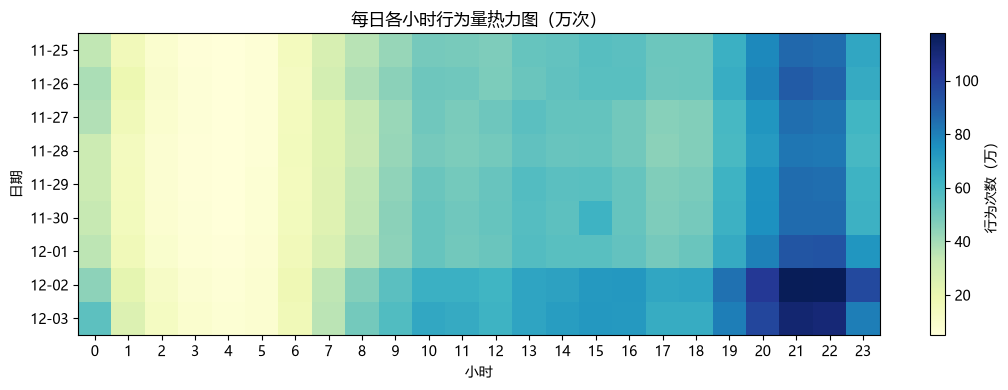

In [13]:
pivot = data.groupby(['day_idx', 'hour']).size().unstack(fill_value=0)
pivot.index = [(pd.Timestamp('2017-01-01') + pd.Timedelta(days=int(d) - 1)).strftime('%m-%d')
               for d in pivot.index]

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(pivot.values / 1e4, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel('小时')
ax.set_ylabel('日期')
ax.set_title('每日各小时行为量热力图（万次）')
plt.colorbar(im, ax=ax, label='行为次数（万）')
plt.tight_layout()
plt.show()

## 结论

**1. 规模**：9 天共 1.0 亿条行为，其中浏览 8,966 万次（占 89.58%）；覆盖 98.8 万独立用户；
日均浏览约 996 万次，日均访客约 77 万人（按天平均），人均每天约 10 次浏览。

**2. 走势**：11-25 ~ 12-01 相当平稳（PV 884~972 万、UV 71~74 万）；
**12-02、12-03 两天跳升约 30%**（PV 1,230 万、UV 97 万、下单量 25.8 万），是 9 天里唯一的高峰。
11-25 也是周六却没有这种跳升，说明不是单纯周末效应，更像临近双 12 的预热拉动。

**3. 时段**：早 8 点起爬升，10-18 点平稳（每小时约占 4.7%~5.4%）；
**20-22 点是全天峰值**，三小时合计约占 24% 的浏览和 21% 的下单，其中 21 点单小时最高（8.41%）；
凌晨 3-5 点最冷清（每小时不足 1%）。→ 推送、活动上线应放在 19:30-21:00。

**4. 行为结构**：浏览 : 加购 : 收藏 : 购买 ≈ 89.6 : 5.5 : 2.9 : 2.0，
浏览到购买的粗转化约 2.2%，加购 + 收藏合计 8.4%，意向行为并不算少。
下一步值得做「浏览 → 加购/收藏 → 购买」的漏斗，看具体流失在哪一环。